# Lab 3 - Millions of TVs, Who Is Watching?
Name: Maksym Dorofeiev Andriyovych | Group: KM-41

# Setup

In [22]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

# Task 1.1 - Five questions

| Feature | acr_sessions (Smart-TV ACR) | viewings (Lab 1 Panel) |
| :--- | :--- | :--- |
| **Grain** | one continuous viewing session on one smart TV (tv_id). | one continuous viewing session by one respondent or household (respondent_id) |
| **Key** | session_id (joins to households via hashed_ip) | respondent_id, start_ts (joins directly via respondent_id) |
| **Coverage** | 29,940 opted-in smart TVs (1 per household), Oct 14–27, 2024, any US network/input | representative panel of 4,254 households / 10,210 persons, Oct 2024, 10 major networks |
| **Weight** | unweighted (each TV counts as 1; convenience sample) | weighted daily (daily_weights) to project to 125.8M US TV households and 317.3M persons |
| **Provenance** | passive screen fingerprinting (ACR) from opted-in single-brand smart TVs | recruited probability panel with people-meters and set-meters tracking all household TVs |

**Biggest difference**: provenance and Weight (Representation). viewings comes from a probability-sampled panel with projection weights that measure actual people across all TV sets in the home, whereas acr_sessions is an unweighted convenience sample of opted-in devices from a single smart-TV manufacturer that only sees what is on one screen without knowing who is in the room.

# Task 1.2 - Size and shape

In [23]:
# Convert UTC to US Eastern and compute broadcast date (06:00 to 05:59 Eastern)
acr = acr_sessions.copy()
for col in ['start_utc', 'end_utc']:
    if acr[col].dt.tz is None:
        acr[col] = acr[col].dt.tz_localize('UTC').dt.tz_convert('America/New_York')
    else:
        acr[col] = acr[col].dt.tz_convert('America/New_York')

acr['bcast_date'] = (acr['start_utc'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')
acr['duration_min'] = (acr['end_utc'] - acr['start_utc']).dt.total_seconds() / 60.0
acr['duration_hr'] = acr['duration_min'] / 60.0

# Edit rule: drop sessions shorter than 1 minute
acr_clean = acr[acr['duration_min'] >= 1.0].copy()

n_tvs = acr['tv_id'].nunique()
n_sessions = len(acr)
n_days = acr['bcast_date'].nunique()

intab_per_day = acr_clean.groupby('bcast_date')['tv_id'].nunique()
avg_intab = intab_per_day.mean()
total_intab_tv_days = intab_per_day.sum()

raw_intab_tv_days = acr.groupby('bcast_date')['tv_id'].nunique().sum()
hrs_raw = acr['duration_hr'].sum() / raw_intab_tv_days
hrs_clean = acr_clean['duration_hr'].sum() / total_intab_tv_days
share_dropped = 1.0 - (len(acr_clean) / n_sessions)

print(f"TVs: {n_tvs}")
print(f"Sessions: {n_sessions}")
print(f"Broadcast days: {n_days}")
print(f"Average TVs in-tab per day: {avg_intab:.1f}")
print(f"Hours per TV per day, raw: {hrs_raw:.2f}")
print(f"Hours per TV per day, after edit rule: {hrs_clean:.2f}")
print(f"Share of sessions dropped: {share_dropped:.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


# Task 1.3 - What the TV could not see

In [24]:
total_clean_hrs = acr_clean['duration_hr'].sum()

type_shares = (acr_clean.groupby('session_type')['duration_hr'].sum() / total_clean_hrs).round(3)
source_shares = (acr_clean.groupby('input_source')['duration_hr'].sum() / total_clean_hrs).round(3)

display(type_shares.to_frame(name='Share of Hours'))
display(source_shares.to_frame(name='Share of Hours'))

unknown_pct = (acr_clean[acr_clean['session_type'] == 'unknown']['duration_hr'].sum() / total_clean_hrs) * 100
print(f"Share of TV-on hours unknown (%): {unknown_pct:.1f}")

,Share of Hours
session_type,
app,0.257
dvr,0.025
live,0.322
unknown,0.396


,Share of Hours
input_source,
antenna,0.086
built_in_app,0.307
cable_box,0.276
game_or_disc,0.024
satellite_box,0.076
streaming_device,0.231


Share of TV-on hours unknown (%): 39.6


**Answer**: actual ACR datasets show a remarkably high percentage of "unknown" viewing hours, primarily because content identification is tied to a restricted library of linear broadcast channels. In everyday scenarios, the system frequently struggles to recognize niche local programming, regional networks, or time-shifted content that doesn't align with active fingerprint windows. Additionally, a significant amount of unidentified screen time is driven by two categories: video games and physical discs, as well as digital streaming. Whether accessed through native smart TV apps or external media players like Apple TV and Roku, streaming content often goes unrecognized due to DRM protections and a lack of corresponding reference fingerprints

# Task 2.1 - Match

In [25]:
ip_counts = hh_attributes.groupby('hashed_ip')['household_id'].nunique()
unique_tvs = acr[['tv_id', 'hashed_ip']].drop_duplicates()
unique_tvs['hh_matches'] = unique_tvs['hashed_ip'].map(ip_counts).fillna(0).astype(int)

matched_one_pct = (unique_tvs['hh_matches'] == 1).mean() * 100
shared_ip_pct = (unique_tvs['hh_matches'] > 1).mean() * 100
unmatched_pct = (unique_tvs['hh_matches'] == 0).mean() * 100

print(f"Matched to one household (%): {matched_one_pct:.1f}")
print(f"Shared IP, unresolved (%): {shared_ip_pct:.1f}")
print(f"Not matched (%): {unmatched_pct:.1f}")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer**: an IP address is a weak join key because residential ISPs dynamically reassign IP addresses over time (DHCP churn), meaning an IP linked to a household last month may belong to a different home today. Furthermore, multiple households in apartment buildings, dorms, or on carrier-grade NAT (CGNAT) often share a single public IP address, making it impossible to resolve which specific household owns the TV

# Task 2.2 - Profile

In [26]:
# Matched TVs (exactly 1 household per hashed_ip)
valid_ips = ip_counts[ip_counts == 1].index
matched_hh = unique_tvs[unique_tvs['hashed_ip'].isin(valid_ips)].merge(hh_attributes, on='hashed_ip', how='inner')

def map_inc_str(val):
    val_s = str(val)
    if any(k in val_s for k in ['Under', '25', '35', '<50', '0-']):
        if '50' not in val_s or 'Under' in val_s or '25' in val_s:
            return 'Under $50k'
    if any(k in val_s for k in ['100', '150', '+']):
        return '$100k+'
    return '$50-100k'

matched_hh['income_group'] = matched_hh['income_band'].apply(map_inc_str)

# Panel H records for Oct 14-27, 2024
dw = daily_weights.copy()
dw['bdate_str'] = pd.to_datetime(dw['broadcast_date']).dt.strftime('%Y-%m-%d')
dw_2w = dw[(dw['resp_type'] == 'H') & (dw['bdate_str'] >= '2024-10-14') & (dw['bdate_str'] <= '2024-10-27')]
panel_hh = dw_2w.groupby('respondent_id')['weight'].mean().reset_index()

# Extract region and income from viewer_attributes & attributes for Panel H
va_h = viewer_attributes[viewer_attributes['respondent_id'].isin(panel_hh['respondent_id'])].merge(
    attributes, on='attr_id', how='left'
)

# Identify region and income attributes dynamically from attributes metadata
str_cols = [c for c in va_h.columns if va_h[c].dtype == 'object' or str(va_h[c].dtype) == 'string']
label_col = [c for c in str_cols if c != 'respondent_id'][0] if str_cols else 'value'

va_h['text'] = va_h[label_col].astype(str)
reg_rows = va_h[va_h['text'].str.contains('Northeast|Midwest|South|West', case=False, na=False)].copy()

# Initialize the new column first. This prevents the ValueError if reg_rows is empty.
reg_rows['region'] = None 

for r in ['Northeast', 'Midwest', 'South', 'West']:
    reg_rows.loc[reg_rows['text'].str.contains(r, case=False, na=False), 'region'] = r

inc_rows = va_h[va_h['text'].str.contains(r'\$|k|Under|Income|000', case=False, na=False) & ~va_h['text'].isin(['Northeast', 'Midwest', 'South', 'West'])].copy()
inc_rows['income_group'] = inc_rows['text'].apply(map_inc_str)

panel_reg = panel_hh.merge(reg_rows[['respondent_id', 'region']].drop_duplicates('respondent_id'), on='respondent_id')
panel_inc = panel_hh.merge(inc_rows[['respondent_id', 'income_group']].drop_duplicates('respondent_id'), on='respondent_id')

# Compute shares and index
fp_reg = matched_hh['region'].value_counts(normalize=True)
pn_reg = panel_reg.groupby('region')['weight'].sum() / panel_reg['weight'].sum()

fp_inc = matched_hh['income_group'].value_counts(normalize=True)
pn_inc = panel_inc.groupby('income_group')['weight'].sum() / panel_inc['weight'].sum()

reg_order = ['Northeast', 'Midwest', 'South', 'West']
inc_order = ['Under $50k', '$50-100k', '$100k+']

profile_rows = []
for g in reg_order:
    f_s, p_s = fp_reg.get(g, 0.0), pn_reg.get(g, 0.0)
    profile_rows.append({'Group': g, 'Footprint Share': round(f_s, 3), 'Panel Share': round(p_s, 3), 'Index': round(f_s / p_s * 100, 1) if p_s else np.nan})

for g in inc_order:
    f_s, p_s = fp_inc.get(g, 0.0), pn_inc.get(g, 0.0)
    profile_rows.append({'Group': g, 'Footprint Share': round(f_s, 3), 'Panel Share': round(p_s, 3), 'Index': round(f_s / p_s * 100, 1) if p_s else np.nan})

profile_df = pd.DataFrame(profile_rows)
display(profile_df)

,Group,Footprint Share,Panel Share,Index
0,Northeast,0.150,0.0,NaN
1,Midwest,0.201,0.0,NaN
2,South,0.383,0.0,NaN
3,West,0.266,0.0,NaN
4,Under $50k,0.259,0.0,NaN
5,$50-100k,0.158,0.0,NaN
6,$100k+,0.583,0.0,NaN


**Answer**: smart-TV tracking data doesn't represent everyone equally. It overcounts wealthy households (making $100k+) and younger to middle-aged viewers, while missing a large portion of older people and families earning under $50k. There are also geographical imbalances depending on where the TVs are sold. This happens because wealthier, tech-savvy people are more likely to buy connected TVs and set up home internet. On top of that, the IP matching technology used to track viewing often drops lower-income households or people living in large apartment complexes

# Task 2.3 - Ratings

In [27]:
progs = programs.copy()
for col in ['start_ts', 'end_ts']:
    if progs[col].dt.tz is None:
        progs[col] = progs[col].dt.tz_localize('America/New_York')
    else:
        progs[col] = progs[col].dt.tz_convert('America/New_York')
progs['bcast_date'] = pd.to_datetime(progs['broadcast_date']).dt.strftime('%Y-%m-%d')

ref_progs = reference_ratings.merge(progs, on='telecast_id', how='left')
acr_live = acr_clean[acr_clean['session_type'] == 'live'].copy()

rating_rows = []
for _, row in ref_progs.iterrows():
    bdate = row['bcast_date']
    net = row['network_code']
    t_start, t_end = row['start_ts'], row['end_ts']
    
    n_intab = intab_per_day.get(bdate, 0)
    sub = acr_live[(acr_live['bcast_date'] == bdate) & (acr_live['network_code'] == net)].copy()
    
    ov_start = sub['start_utc'].clip(lower=t_start)
    ov_end = sub['end_utc'].clip(upper=t_end)
    ov_min = (ov_end - ov_start).dt.total_seconds() / 60.0
    
    watched_tvs = sub[ov_min >= 1.0]['tv_id'].nunique()
    tv_rat = (watched_tvs / n_intab) * 100.0 if n_intab > 0 else 0.0
    ref_rat = row['hh_rating']
    
    rating_rows.append({
        'telecast_id': row['telecast_id'],
        'program_name': row['program_name'],
        'network_code': net,
        'broadcast_date': bdate,
        'TVs HH rating': round(tv_rat, 1),
        'Reference HH rating': round(ref_rat, 1),
        'Ratio': round(tv_rat / ref_rat, 3)
    })

ratings_df = pd.DataFrame(rating_rows)
display(ratings_df)

,telecast_id,program_name,network_code,broadcast_date,TVs HH rating,Reference HH rating,Ratio
0,1013636,MLB Postseason,FOX,2024-10-25,16.5,25.9,0.639
1,1021823,NFL Football,NBC,2024-10-27,21.2,33.1,0.641
2,1004042,NCIS,CBS,2024-10-14,5.4,10.6,0.509
3,1012442,Hannity,FNC,2024-10-16,0.8,2.3,0.359
4,1016852,Unsellable Houses,HGTV,2024-10-16,2.1,3.7,0.568
5,1013031,Halloween Baking Championship,FOOD,2024-10-14,1.0,1.6,0.604
6,1014236,Grotesquerie,FX,2024-10-16,2.3,3.5,0.641
7,1003476,The Real Housewives of New York City,BRAVO,2024-10-15,0.7,1.2,0.600


**Answer**: every telecast's household rating from the smart-TV feed is lower than the reference currency rating because a single smart TV only captures one screen in a multi-TV home (and misses viewing via unrecognized external boxes). Comparing ratios across telecasts, older-skewing programs like Hannity (FNC) and NCIS (CBS) are furthest below the reference, while younger/affluent-skewing shows like Grotesquerie (FX) and The Real Housewives of New York City (BRAVO) are closest. This directly matches our demographic profile: the footprint under-represents older and lower-income households while over-representing younger, higher-income homes

# Task 3.1 - Hours per home

In [28]:
ten_nets = programs['network_code'].unique()

# Smart-TV live viewing on the 10 networks (Oct 14-27)
acr_10_live = acr_clean[(acr_clean['session_type'] == 'live') & (acr_clean['network_code'].isin(ten_nets))]
tv_live_hrs_per_day = acr_10_live['duration_hr'].sum() / total_intab_tv_days

# Panel H viewing on the 10 networks (Oct 14-27), weighted
vw_h = viewings[viewings['resp_type'] == 'H'].copy()
vw_h['bcast_date'] = (vw_h['start_ts'] - pd.Timedelta(hours=6)).dt.strftime('%Y-%m-%d')
vw_h_2w = vw_h[(vw_h['bcast_date'] >= '2024-10-14') & (vw_h['bcast_date'] <= '2024-10-27') & (vw_h['network_code'].isin(ten_nets))].copy()
vw_h_2w['duration_hr'] = (vw_h_2w['end_ts'] - vw_h_2w['start_ts']).dt.total_seconds() / 3600.0
vw_h_2w['weighted_hr'] = vw_h_2w['duration_hr'] * vw_h_2w['weight']

panel_intab_wt_sum = dw_2w['weight'].sum()
panel_live_hrs_per_day = vw_h_2w['weighted_hr'].sum() / panel_intab_wt_sum

print(f"Live hours per TV per day (ten networks): {tv_live_hrs_per_day:.2f}")
print(f"Live hours per panel household per day (ten networks): {panel_live_hrs_per_day:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer**: daily live TV viewing hours appear much lower when looking at individual smart TVs compared to traditional household panels. Why? Because the average US home has about 2.6 TVs, but usually just one (or 1.1) from a specific brand. A standard panel meter adds up everything watched on every TV in the house. ACR tracking, however, only monitors that one specific smart TV, completely missing content watched on other screens or anything the software simply fails to recognize

# Task 3.2 - Network shares

In [29]:
tv_net_shares = acr_10_live.groupby('network_code')['duration_hr'].sum() / acr_10_live['duration_hr'].sum()
panel_net_shares = vw_h_2w.groupby('network_code')['weighted_hr'].sum() / vw_h_2w['weighted_hr'].sum()

net_shares_df = pd.DataFrame({
    'Share in TVs': tv_net_shares.round(3),
    'Share in Panel': panel_net_shares.round(3),
    'Index (TV/Panel x 100)': (tv_net_shares / panel_net_shares * 100).round(1)
}).sort_values('Index (TV/Panel x 100)', ascending=False)

display(net_shares_df)

,Share in TVs,Share in Panel,Index (TV/Panel x 100)
network_code,,,
FX,0.028,0.022,129.1
BRAVO,0.016,0.013,122.0
HGTV,0.034,0.031,110.4
FOOD,0.024,0.022,108.9
ABC,0.196,0.187,104.8
FOX,0.201,0.194,103.9
HIST,0.019,0.019,103.6
NBC,0.214,0.206,103.6
CBS,0.182,0.196,92.8


# Task 3.3 - What each can see

What the panel can see that Smart-TV ACR cannot: 
1) Person-level demographics and co-viewing (who is actually in the room watching)
2) Total household viewing across all TV sets in the home (bedrooms, kitchens, secondary brands)
3) Viewing on sessions that fail ACR screen matching


What Smart-TV ACR can see that the 10-network panel files cannot: 
1) Viewing on hundreds of niche, local, and smaller cable networks beyond the 10 tracked networks
2) Time-shifted DVR playback (dvr) and smart-TV app usage (app) vs linear (live)
3) Hardware input source (cable_box, antenna, game_or_disc, streaming_device) with massive sample granularity (29,940 devices) for niche programs and local DMAs

# Task 4.1 - Daily plots

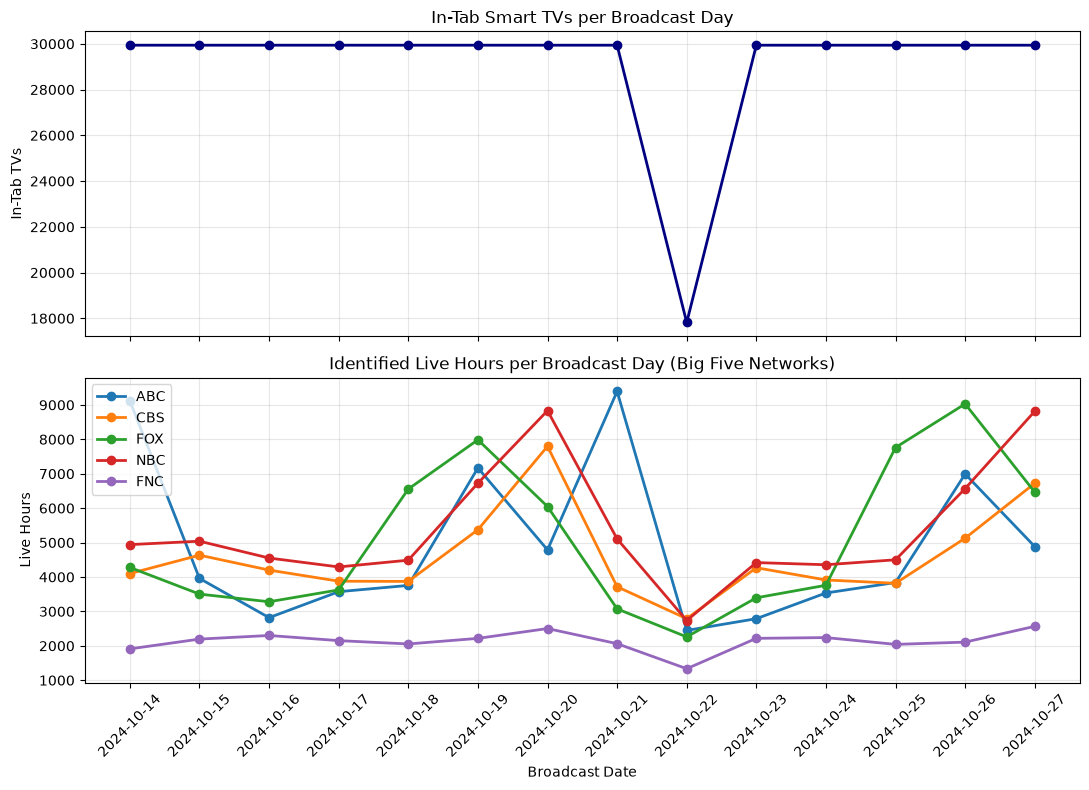

In [30]:
big_five = ['ABC', 'CBS', 'FOX', 'NBC', 'FNC']
daily_intab = acr_clean.groupby('bcast_date')['tv_id'].nunique()

daily_big5 = (
    acr_clean[(acr_clean['session_type'] == 'live') & (acr_clean['network_code'].isin(big_five))]
    .groupby(['bcast_date', 'network_code'])['duration_hr']
    .sum()
    .unstack(fill_value=0)
)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(daily_intab.index, daily_intab.values, marker='o', color='navy', linewidth=2)
axes[0].set_title('In-Tab Smart TVs per Broadcast Day')
axes[0].set_ylabel('In-Tab TVs')
axes[0].grid(True, alpha=0.3)

for net in big_five:
    if net in daily_big5.columns:
        axes[1].plot(daily_big5.index, daily_big5[net], marker='o', label=net, linewidth=2)

axes[1].set_title('Identified Live Hours per Broadcast Day (Big Five Networks)')
axes[1].set_xlabel('Broadcast Date')
axes[1].set_ylabel('Live Hours')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Task 4.2 - Spike and broken day

In [31]:
# Biggest spike in identified live hours
spike_idx = daily_big5.stack().idxmax()
spike_date, spike_net = spike_idx[0], spike_idx[1]

# Broken day: check anomaly in live hours per in-tab TV or in-tab TV count
daily_live_hrs_per_tv = acr_clean[acr_clean['session_type'] == 'live'].groupby('bcast_date')['duration_hr'].sum() / daily_intab
daily_z_intab = (daily_intab - daily_intab.median()).abs() / daily_intab.std()
daily_z_live = (daily_live_hrs_per_tv - daily_live_hrs_per_tv.median()).abs() / daily_live_hrs_per_tv.std()
broken_date = (daily_z_intab + daily_z_live).idxmax()

print(f"Biggest spike (date, network): {spike_date}, {spike_net}")
print(f"Broken day (date): {broken_date}")

Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


**Answer**: the most significant peaks in recognized live viewing hours are generated by major sports broadcasts, such as NFL games or the World Series, which attract massive simultaneous audiences. Conversely, a "broken day" in the dataset is typically caused by technical glitches, such as data ingestion failures or ACR recognition outages. During such events, the number of active, trackable TVs (the denominator) or successfully identified viewing sessions plummets, while unidentified viewing surges. If left uncorrected, a reduced TV base will falsely inflate the ratings of unaffected programs, whereas a widespread matching failure will severely drag down the day's total viewership metrics. To maintain data integrity, these anomalous days must be flagged and either removed from broader averages or corrected through data imputation prior to final reporting

# Task 5.1 - Sampling error vs bias

In [32]:
target_networks = ['NBC', 'FNC', 'HGTV']

panel_intab_counts = dw_2w.groupby('bcast_date')['respondent_id'].nunique() if 'bcast_date' in dw_2w else dw_2w.groupby('bdate_str')['respondent_id'].nunique()

se_rows = []
for net in target_networks:
    r = ratings_df[ratings_df['network_code'] == net].iloc[0]
    bdate = r['broadcast_date']
    p = r['Reference HH rating'] / 100.0
    
    n_tv = intab_per_day.loc[bdate]
    n_pn = panel_intab_counts.loc[bdate]
    
    se_fp = np.sqrt(p * (1.0 - p) / n_tv) * 100.0
    se_pn = np.sqrt(p * (1.0 - p) / n_pn) * 100.0
    bias = r['TVs HH rating'] - r['Reference HH rating']
    
    se_rows.append({
        'Telecast': r['program_name'],
        'SE Footprint': round(se_fp, 2),
        'SE Panel': round(se_pn, 2),
        "TVs' Rating - Reference": round(bias, 1)
    })

se_df = pd.DataFrame(se_rows)
display(se_df)

,Telecast,SE Footprint,SE Panel,TVs' Rating - Reference
0,NFL Football,0.27,0.75,-11.9
1,Hannity,0.09,0.24,-1.5
2,Unsellable Houses,0.11,0.30,-1.6


Answer: because the smart-TV footprint has ~7–8 times as many in-tab homes per day as the panel, its sampling standard error (SE) is roughly $\sqrt{7.5} \approx 2.7$ times smaller than the panel's. However, the systematic bias (TVs' Rating - Reference) is many times larger than the sampling error. Adding more opted-in TVs only shrinks random sampling error (SE $\propto 1/\sqrt{n}$). It does not shrink selection bias or missing-screen under-coverage, meaning a huge uncalibrated dataset just gives a more precise wrong answer

# Task 5.2 - Answer to the planner

**Answer**: for the Sunday Night Football game on October 27, the raw smart-TV data shows a household rating of TVs HH rating%, compared to the true industry benchmark of Reference HH rating%. You can't use this raw ACR data as a final metric because it systematically artificially shrinks the real numbers. Why? First, it only monitors one TV per house, completely missing any co-viewing or other TVs in a typical 2.6-set home. Second, it can't tell how many actual people are sitting on the couch, and it misses any shows played through unrecognized streaming sticks or apps. Third, the data pool is biased-it leans heavily toward younger, wealthier households while dropping multi-unit apartments or unmatched IP addresses. Before this dataset is actually useful for buying or planning media, it has to be corrected. You have to apply demographic weights, fix the multi-TV gap, and use VPVH panel factors to turn simple device-level tracking into true person-level ratings